# Analyse Exeperiments Results #

In [90]:
import numpy as np
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

import sys
sys.path.append("/home/gavrilev/Thesis/src")

from utils.plot_utils import plot_horizontal_metric, plot_grouped_metrics

## 15/03/2026 - Ablation Study - Stratified 5-Fold CV

The following experiments are designed to examine the contribution of predicted RNA 3D structures to RNA–small molecule binding affinity prediction.

The predicted RNA 3D structures were obtained using the AlphaFold3 server. These structures were then processed using the pre-trained gRNAde framework, originally developed for inverse RNA folding. We extracted the pre-trained weights (via Hugging Face) and fine-tuned only the GNN encoder, which takes RNA structural information as input and produces node and edge representations.

In addition, we introduced a cross-modal fusion mechanism named **BiDirectionalCrossFusion**, which integrates RNA graph features with sequence-based language embeddings. This mechanism is based on nucleotide-level cross-attention, where each graph node *i* corresponds to nucleotide *i* in both the structural graph and the sequence embedding space.

Overall, the ablation study evaluates the following model configurations:

1. **w/o 3D structure** – excludes predicted RNA 3D structures (i.e., no AlphaFold3 + gRNAde features)
2. **w/o sequence** – excludes pre-trained RNA language model embeddings (ERNIE-RNA, RiNALMo)
3. **w/o fusion** – removes the BiDirectionalCrossFusion module (features are combined via simple concatenation)
4. **MultiStructRSA (frozen)** – full model with frozen gRNAde weights (to assess the contribution of fine-tuning)
5. **MultiStructRSA (full)** – full model with trainable gRNAde encoder

In [97]:
EXP_1503_PATH = '/home/gavrilev/Thesis/src/results/table_results/cv_all_1503.csv'

In [98]:
exp_1503_df = pd.read_csv(EXP_1503_PATH)
exp_1503_df

,exp,family,n_samples,rmse_mean,p_mean,s_mean,r2_mean
0,ex1,all_families_concat,1439,0.885357,0.777723,0.789176,0.595684
1,ex2,all_families_concat,1439,0.899184,0.766101,0.772115,0.583285
2,ex5,all_families_concat,1439,0.885466,0.775474,0.786823,0.596659
3,ex3,all_families_concat,1439,0.991107,0.707050,0.697247,0.494676
4,ex4,all_families_concat,1439,0.985013,0.713572,0.705010,0.501024
5,ex5v2,all_families_concat,1439,0.885466,0.775474,0.786823,0.596659
6,ex7,all_families_concat,1439,0.874824,0.782639,0.784438,0.606360
7,ex9,all_families_concat,1439,0.851125,0.796580,0.803892,0.627542
8,ex8,all_families_concat,1439,0.848298,0.796601,0.803049,0.630332
9,ex10,all_families_concat,1439,0.874880,0.784813,0.792406,0.606698


In [99]:
exp_1503_df = exp_1503_df.iloc[[2, 7, 9, 10, 11], :]
exp_1503_df

,exp,family,n_samples,rmse_mean,p_mean,s_mean,r2_mean
2,ex5,all_families_concat,1439,0.885466,0.775474,0.786823,0.596659
7,ex9,all_families_concat,1439,0.851125,0.796580,0.803892,0.627542
9,ex10,all_families_concat,1439,0.874880,0.784813,0.792406,0.606698
10,ex11,all_families_concat,1439,0.872877,0.781796,0.791692,0.607381
11,ex6,all_families_concat,1439,0.931464,0.750617,0.755045,0.553320


In [100]:
exp_1503_df = exp_1503_df.copy()
exp_1503_df['exp_description'] = ['w/o 3D Struct', 'MultiStructRSA', 'MultiStructRSA (frozen)', 'w/o Fusion', 'w/o Seq']

In [101]:
exp_1503_df.drop(columns=['exp', 'family', 'n_samples', 'r2_mean'], inplace=True)
exp_1503_df

,rmse_mean,p_mean,s_mean,exp_description
2,0.885466,0.775474,0.786823,w/o 3D Struct
7,0.851125,0.796580,0.803892,MultiStructRSA
9,0.874880,0.784813,0.792406,MultiStructRSA (frozen)
10,0.872877,0.781796,0.791692,w/o Fusion
11,0.931464,0.750617,0.755045,w/o Seq


In [102]:
order = ['w/o 3D Struct', 'w/o Seq', 'w/o Fusion', 'MultiStructRSA (frozen)', 'MultiStructRSA']
exp_1503_df['exp_description'] = pd.Categorical(exp_1503_df['exp_description'], categories=order,ordered=True)

exp_1503_df = exp_1503_df.sort_values('exp_description').reset_index(drop=True)
cols = ['exp_description'] + [c for c in exp_1503_df.columns if c != 'exp_description']
exp_1503_df = exp_1503_df[cols]

In [103]:
exp_1503_df

,exp_description,rmse_mean,p_mean,s_mean
0,w/o 3D Struct,0.885466,0.775474,0.786823
1,w/o Seq,0.931464,0.750617,0.755045
2,w/o Fusion,0.872877,0.781796,0.791692
3,MultiStructRSA (frozen),0.874880,0.784813,0.792406
4,MultiStructRSA,0.851125,0.796580,0.803892


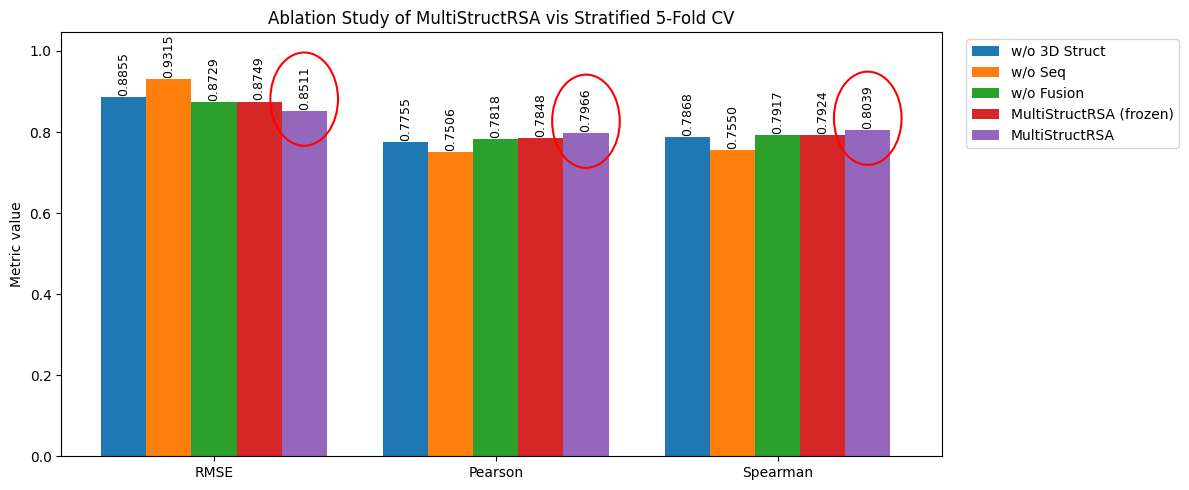

In [111]:
metric_cols = ["rmse_mean", "p_mean", "s_mean"]

metric_labels = {
    "rmse_mean": "RMSE",
    "p_mean": "Pearson",
    "s_mean": "Spearman"
}

exp_order = [
    "w/o 3D Struct",
    "w/o Seq",
    "w/o Fusion",
    "MultiStructRSA (frozen)",
    "MultiStructRSA"
]

plot_grouped_metrics(
    df=exp_1503_df,
    metric_cols=metric_cols,
    exp_col="exp_description",
    exp_order=exp_order,
    metric_labels=metric_labels,
    title="Ablation Study of MultiStructRSA vis Stratified 5-Fold CV",
    lower_is_better=["rmse_mean"]
)

plt.show()

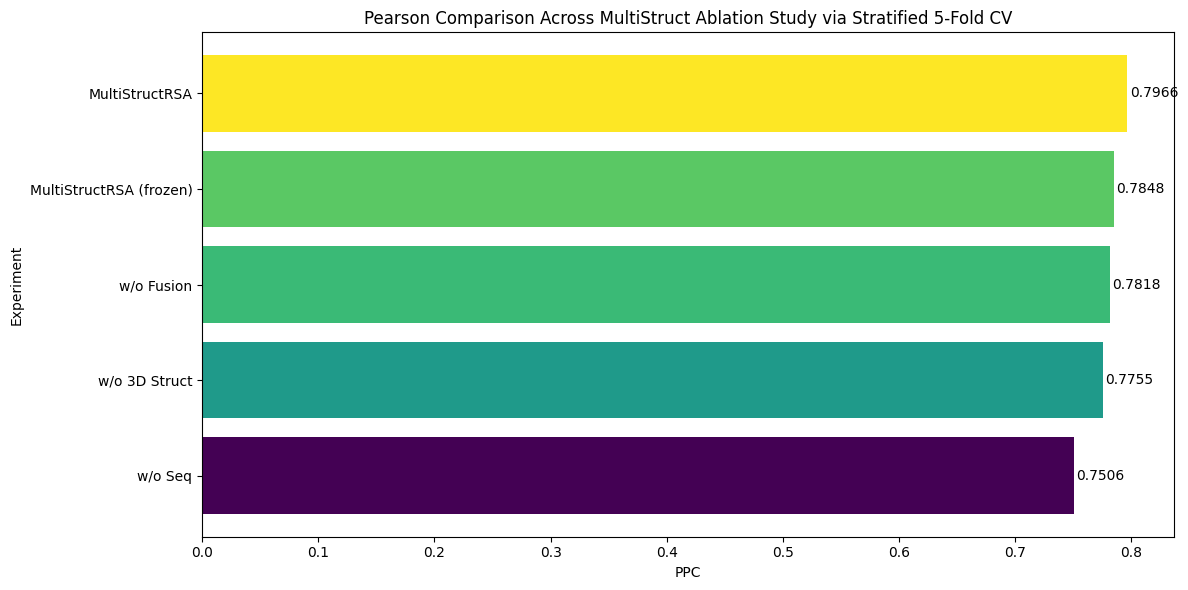

In [110]:
plot_horizontal_metric(
    df=exp_1503_df,
    label_col="exp_description",
    value_col="p_mean",
    title="Pearson Comparison Across MultiStruct Ablation Study via Stratified 5-Fold CV",
    xlabel="PPC",
    ylabel="Experiment",
    sort_ascending=True
)

plt.show()